# Task 37: Logistic Regression (Titanic Dataset)
**Track:** AI & ML Track  

### Objective
Build a basic binary classification model using **Logistic Regression** on the Titanic dataset to predict passenger survival (`survived`), and understand how classification models work and evaluate their predictions.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Titanic dataset
df = pd.read_csv('titanic.csv')

# Display basic information and first few rows
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values per column:")
print(df.isnull().sum())

Dataset Shape: (891, 15)

First 5 rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



Missing values per column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


### Data Preparation and Feature Selection
For this basic model, we will select key numerical and categorical features (`pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`) and handle missing values by filling missing ages with the median. We will also encode categorical variables like `sex`.

In [2]:
# Select features and target variable
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare']
target = 'survived'

data = df[features + [target]].copy()

# Handle missing values for 'age' using the median
data['age'] = data['age'].fillna(data['age'].median())

# Encode 'sex' column (male: 0, female: 1)
data['sex'] = data['sex'].map({'male': 0, 'female': 1})

# Separate features (X) and target (y)
X = data[features]
y = data[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
data.head()

Features shape: (891, 6)
Target shape: (891,)


,pclass,sex,age,sibsp,parch,fare,survived
0,3,0,22.0,1,0,7.2500,0
1,1,1,38.0,1,0,71.2833,1
2,3,1,26.0,0,0,7.9250,1
3,1,1,35.0,1,0,53.1000,1
4,3,0,35.0,0,0,8.0500,0


### Model Training & Evaluation
We will split our prepared dataset into training (80%) and testing (20%) sets, train a Logistic Regression model, and evaluate its performance using accuracy and a confusion matrix.

Model Accuracy: 81.01%

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.88      0.84       105
           1       0.80      0.72      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



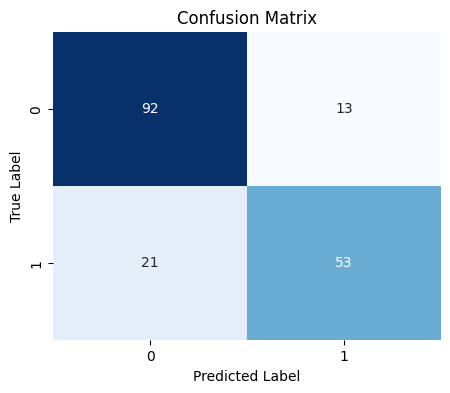

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Split data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Logistic Regression model
model = LogisticRegression(max_iter=500)
model.fit(X_train, y_train)

# Make predictions on the test data
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Short Explanation of the Model
**Logistic Regression** is a supervised machine learning algorithm primarily used for binary classification problems (predicting categorical outcomes, like 0 or 1, Yes or No, Survived or Did Not Survive). 

Instead of fitting a straight line like Linear Regression, Logistic Regression applies the **Sigmoid function** to map predicted values into probabilities between 0 and 1. A threshold (typically 0.5) is then used to assign the class label:
- If probability $\ge 0.5$, predict **Class 1** (Survived).
- If probability $< 0.5$, predict **Class 0** (Did Not Survive).

---

### Interview Questions & Answers

#### Q1: What is Logistic Regression?
**Answer:** Logistic Regression is a statistical and machine learning classification algorithm used to predict the probability of a categorical dependent variable (usually binary, taking values 0 or 1) based on one or more independent predictor features.

#### Q2: Why is Logistic Regression used for classification?
**Answer:** While Linear Regression outputs continuous values ranging from negative to positive infinity, classification requires predicting discrete classes (e.g., 0 or 1). Logistic Regression uses the sigmoid (logistic) function to constrain its output between 0 and 1, representing a clear probability score that can easily be thresholded into classes.

#### Q3: What is the difference between Linear and Logistic Regression?
**Answer:** 
* **Linear Regression** predicts continuous numerical outcomes (e.g., house prices, temperature) and uses a straight-line equation $y = mx + c$.
* **Logistic Regression** predicts categorical/binary outcomes (e.g., spam/not spam, survived/died) and uses the non-linear S-curve sigmoid function $\sigma(z) = \frac{1}{1 + e^{-z}}$ to output probabilities.